# 04. Model comparison

**Thesis:** Machine-Learning Prediction of Shear-Wave Velocity in the Dampier Sub-basin: Accuracy, Errors and Applications (D. Aldosaimani, Curtin University, 2026)

**What this notebook does:** Reads the LOWO results of the five models (notebooks 01–03) and compares their accuracy: mean R² and RMSE, R² in each well, and measured against predicted Vs.

**Used in:** Section 4.1; Appendix A, Table A1

**Needs:** `DATA_DIR`, `LAS_DIR` and the results of notebooks 01–03 (set in the Settings cell below)

**Writes:** Per-well R² and RMSE tables

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import lasio
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


## Settings

In [ ]:
# ---- Settings: set these paths before running ----
DATA_DIR    = Path("../data/processed")   # the eight *_with_formation.csv files (well logs with formation names)
LAS_DIR     = Path("../data/las")         # the eight *_LQC.las files from NOPIMS (project ENO0810814A)
RESULTS_DIR = Path("../results")          # results tables are written here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load well data


In [2]:
data_dir = DATA_DIR

well_logs = {}

for csv_file in sorted(data_dir.glob("*.csv")):
    well_name = csv_file.stem
    df = pd.read_csv(csv_file)
    df.insert(0, "Well Name", well_name)
    well_logs[well_name] = df
    print(f"{well_name}: {len(df)} samples")

data_df = pd.concat(well_logs.values(), ignore_index=True)
print(f"\nLoaded {len(well_logs)} wells, {len(data_df)} total samples")


Angel_1_with_formation: 3657 samples
Angel_3_with_formation: 15205 samples
Egret_2_with_formation: 5287 samples
Lambert_8B_with_formation: 9385 samples
Nereus_1_with_formation: 9273 samples
Persephone_1_with_formation: 9706 samples
Seraph_1_with_formation: 1470 samples
Wanaea_11A_with_formation: 3087 samples

Loaded 8 wells, 57070 total samples


In [3]:
FIGURES_DIR = Path("figures_comparison")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## 2b. Data cleaning (final)

Same two cleaning cells as the Regression notebook (updated_8), so every model and every result uses exactly the same rows:

1. **Remove impossible Vp:** readings faster than the fastest Vp the local minerals could have at zero porosity (Voigt bound of quartz, calcite and illite, illite given quartz properties; Mavko et al., 2009).
2. **Keep only real, unchanged measured Vs** in the 5 measured wells: `VS_ORG` exists in the LAS file and `VS_EDITED_V2` is within 2% of it.

Washouts are kept (tested in the Regression notebook), and no rule based on Vs itself is used. The 3 modelled-only wells only go through step 1.


In [4]:
# --- Remove physically impossible Vp (faster than the rock's own minerals) ---
# Upper limit at each depth = stiffest possible (Voigt) mix of its minerals at zero porosity.
# Clay (illite) is given the stiffness of quartz. Real clay is softer, so this limit is
# deliberately too high: it can only remove readings that no real rock could produce.
# Mineral properties from Mavko et al. (2009): K and mu in GPa, rho in g/cc
QUARTZ  = dict(K=37.0, mu=44.0, rho=2.65)     # solid quartz:  Vp ~ 6010 m/s
CALCITE = dict(K=76.8, mu=32.0, rho=2.71)     # solid calcite: Vp ~ 6640 m/s
REMOVE_IMPOSSIBLE_VP = True

def p_modulus(mineral):                        # P-wave modulus M = K + 4/3 mu
    return mineral['K'] + 4 / 3 * mineral['mu']

solid = data_df[['QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER']].sum(axis=1)
f_calcite = data_df['CALCITE_COMBINER'] / solid      # calcite fraction of the solid rock
f_other = 1 - f_calcite                               # quartz + illite (both given quartz properties)

M   = f_other * p_modulus(QUARTZ) + f_calcite * p_modulus(CALCITE)      # GPa
rho = f_other * QUARTZ['rho'] + f_calcite * CALCITE['rho']               # g/cc
data_df['VP_LIMIT'] = np.sqrt(M / rho) * 1000                             # km/s -> m/s
data_df['vp_impossible'] = data_df['VP_EDITED'] > data_df['VP_LIMIT']

bad = data_df[data_df['vp_impossible']]
print(f"Depths with Vp faster than their minerals allow: {len(bad)}")
display(bad[['Well Name', 'MD', 'Formation', 'VP_EDITED', 'VP_LIMIT']].round(1))

if REMOVE_IMPOSSIBLE_VP:
    data_df = data_df[~data_df['vp_impossible']].reset_index(drop=True)
    print(f"Removed. Rows left: {len(data_df)}")


Depths with Vp faster than their minerals allow: 6


,Well Name,MD,Formation,VP_EDITED,VP_LIMIT
19480,Egret_2_with_formation,2720.5,Withnell Fm,7819.4,6289.8
19644,Egret_2_with_formation,2745.5,Withnell Fm,7181.5,6609.1
19645,Egret_2_with_formation,2745.6,Withnell Fm,7411.0,6609.6
19646,Egret_2_with_formation,2745.8,Withnell Fm,7115.9,6609.4
19749,Egret_2_with_formation,2761.5,Withnell Fm,6502.3,6437.3
53598,Seraph_1_with_formation,2977.1,Angel Fm,6146.5,6008.4


Removed. Rows left: 57064


In [5]:
# --- Keep only real measured Vs (compare VS_EDITED_V2 with VS_ORG from the LAS files) ---

MEASURED_ONLY = True   # remove depths where Vs is not a real measurement
DROP_EDITED   = True   # also remove depths where SLB changed the measured Vs by more than EDIT_TOL
EDIT_TOL      = 0.02   # 2%, same threshold as the checks in Part 3

measured_names = ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']
data_df['VS_ORG'] = np.nan             # modelled-only wells stay empty

for w in measured_names:
    d = lasio.read(list(LAS_DIR.rglob(f"{w}_LQC.las"))[0]).df().reset_index()
    d.columns = d.columns.str.upper()
    d = d.rename(columns={d.columns[0]: 'MD'})
    d = d[['MD', 'VS_ORG']].sort_values('MD')

    idx = data_df['Well Name'].str.contains(w)
    sub = data_df.loc[idx, ['MD']].reset_index().sort_values('MD')
    merged = pd.merge_asof(sub, d, on='MD', direction='nearest', tolerance=0.1)
    data_df.loc[merged['index'], 'VS_ORG'] = merged['VS_ORG'].values

has_org = data_df['VS_ORG'].notna()
edited = has_org & ((data_df['VS_EDITED_V2'] - data_df['VS_ORG']).abs() / data_df['VS_ORG'] > EDIT_TOL)
data_df['VS_MEASURED'] = (has_org & ~edited) if DROP_EDITED else has_org

# Summary per measured well
in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
names = data_df.loc[in_measured_well, 'Well Name']
summary = pd.DataFrame({
    'rows': names.value_counts().sort_index(),
    '% real, unchanged': (100 * (has_org & ~edited)[in_measured_well].groupby(names).mean()).round(1),
    '% real, edited by SLB': (100 * edited[in_measured_well].groupby(names).mean()).round(1),
    '% modelled (no VS_ORG)': (100 * (~has_org)[in_measured_well].groupby(names).mean()).round(1),
})
print(summary)

if MEASURED_ONLY:
    data_df = data_df[~in_measured_well | data_df['VS_MEASURED']].reset_index(drop=True)
    print("\nRows kept per well:")
    print(data_df.groupby('Well Name').size())

    # Check: every row left in the 5 measured wells is a real measurement
    in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
    assert data_df.loc[in_measured_well, 'VS_MEASURED'].all()
    print("\nCheck passed: all rows left in the 5 measured wells are real measured Vs")


                             rows  % real, unchanged  % real, edited by SLB  \
Well Name                                                                     
Egret_2_with_formation       5282               85.3                   14.1   
Lambert_8B_with_formation    9385              100.0                    0.0   
Nereus_1_with_formation      9273               96.5                    2.9   
Persephone_1_with_formation  9706               32.2                    1.0   
Seraph_1_with_formation      1469               53.3                    2.2   

                             % modelled (no VS_ORG)  
Well Name                                            
Egret_2_with_formation                          0.6  
Lambert_8B_with_formation                       0.0  
Nereus_1_with_formation                         0.6  
Persephone_1_with_formation                    66.8  
Seraph_1_with_formation                        44.5  

Rows kept per well:
Well Name
Angel_1_with_formation          3657


## 3. Define well groups

In [6]:
measured_wells = [
    'Egret_2_with_formation',
    'Lambert_8B_with_formation',
    'Nereus_1_with_formation',
    'Persephone_1_with_formation',
    'Seraph_1_with_formation',
]

modelled_wells = [
    'Angel_1_with_formation',
    'Angel_3_with_formation',
    'Wanaea_11A_with_formation',
]


## 4. Define features and target

In [7]:
data_df['RESD_LOG'] = np.log10(data_df['RESD_EDITED'])

features_reg = [
    'GR_EDITED',
    'RHOB_EDITED',
    'NPHI_EDITED',
    'RESD_LOG',
    'VP_EDITED',
]

target_reg = 'VS_EDITED_V2'


## 5. Load LOWO results from each model's saved CSV


In [8]:
csv_dir = RESULTS_DIR

results_linear = pd.read_csv(csv_dir / 'lowo_linear_regression.csv')
results_ridge  = pd.read_csv(csv_dir / 'lowo_ridge_regression.csv')
results_lasso  = pd.read_csv(csv_dir / 'lowo_lasso_regression.csv')
results_mlp    = pd.read_csv(csv_dir / 'lowo_mlp_regression.csv')
results_stack  = pd.read_csv(csv_dir / 'lowo_stacked_ensemble.csv')

results_all = pd.concat(
    [results_linear, results_ridge, results_lasso, results_mlp, results_stack], ignore_index=True
)
results_all['Validation Well'] = results_all['Validation Well'].str.replace('_with_formation', '', regex=False)
results_all


,Model,Validation Well,R2,RMSE,MAE
0,Linear Regression,Egret_2,0.772909,181.366045,122.370716
1,Linear Regression,Lambert_8B,0.901321,93.661428,69.831069
2,Linear Regression,Nereus_1,0.878409,154.923149,128.895534
3,Linear Regression,Persephone_1,-0.086012,316.417694,271.746518
4,Linear Regression,Seraph_1,0.945937,134.684307,104.296521
5,Ridge Regression,Egret_2,0.772701,181.449108,122.366761
6,Ridge Regression,Lambert_8B,0.901381,93.632847,69.836262
7,Ridge Regression,Nereus_1,0.879725,154.082250,128.163874
8,Ridge Regression,Persephone_1,-0.077654,315.197877,270.403540
9,Ridge Regression,Seraph_1,0.945987,134.622533,104.307785


## 6. Model comparison bar chart (mean R² / RMSE, LOWO)


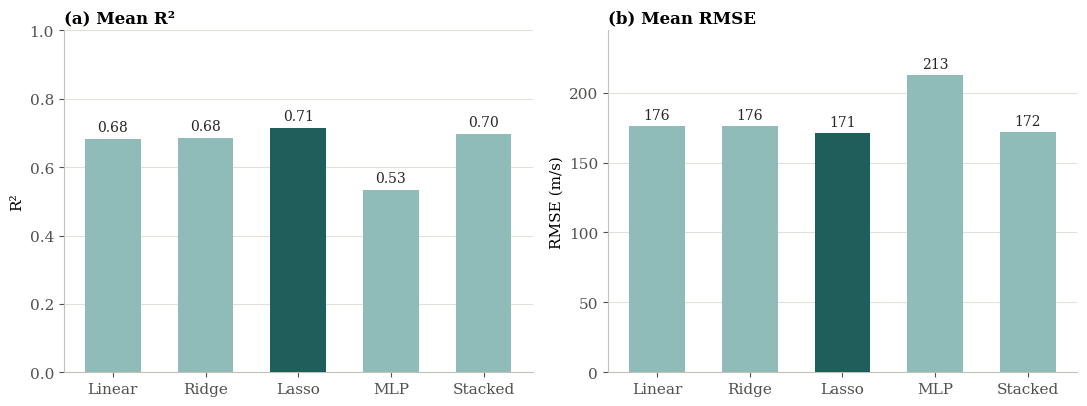

In [15]:
model_order  = ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'MLP Regression', 'Stacked Ensemble']
model_labels = ['Linear', 'Ridge', 'Lasso', 'MLP', 'Stacked']

summary = results_all.groupby('Model')[['R2', 'RMSE']].mean().reindex(model_order)

# one neutral colour; Lasso (the model used in the rest of the study) slightly darker
bar_colors = ['#1f5f5b' if m == 'Lasso Regression' else '#8fbcb8' for m in model_order]
with plt.rc_context({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.edgecolor': '#c3c2b7',
    'axes.linewidth': 0.8,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
}):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

    panels = [('R2',   '(a) Mean R²',   'R²',         (0, 1),                            '{:.2f}', 0.015),
              ('RMSE', '(b) Mean RMSE', 'RMSE (m/s)', (0, summary['RMSE'].max() * 1.15), '{:.0f}', 3)]

    for ax, (col, title, ylabel, ylim, fmt, pad) in zip(axes, panels):
        ax.bar(x, summary[col], width=0.6, color=bar_colors, zorder=3)
        for i, v in enumerate(summary[col]):
            ax.text(i, v + pad, fmt.format(v), ha='center', va='bottom', fontsize=10, color='#262624')
        ax.set_title(title, loc='left', fontweight='bold')
        ax.set_ylabel(ylabel)
        ax.set_ylim(*ylim)
        ax.set_xticks(x)
        ax.set_xticklabels(model_labels)
        ax.grid(axis='y', color='#e1e0d9', linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "model_comparison_bar_chart.png", dpi=300, bbox_inches='tight')
    plt.savefig(FIGURES_DIR / "model_comparison_bar_chart.pdf", bbox_inches='tight')
    plt.show()

## 7. Well × Model R² heatmap (LOWO)

Built from a pivot of `results_all` 

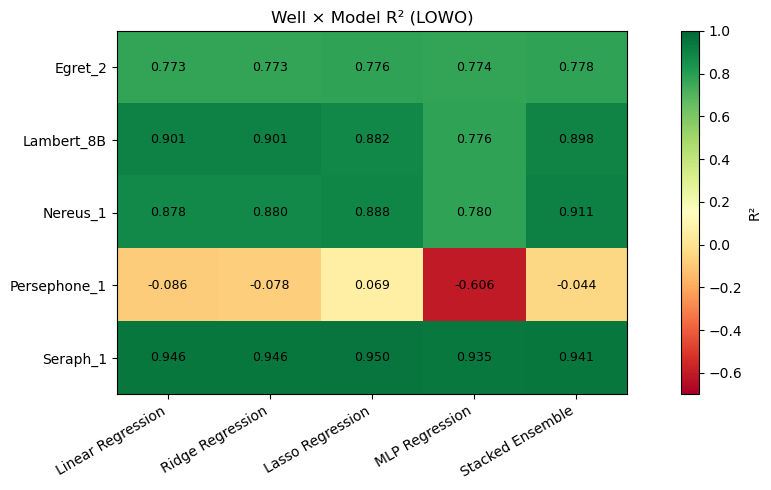

In [10]:
pivot = results_all.pivot(index='Validation Well', columns='Model', values='R2')
pivot = pivot.reindex(columns=model_order)

fig, ax = plt.subplots(figsize=(8, 5))
# Colour scale starts at the lowest R2 (or 0), so low/negative wells are not all shown as the same red
vmin = min(0.0, np.floor(np.nanmin(pivot.values) * 10) / 10)
im = ax.imshow(pivot.values, cmap='RdYlGn', vmin=vmin, vmax=1.0, aspect='auto')

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f'{pivot.values[i, j]:.3f}', ha='center', va='center', color='black', fontsize=9)

ax.set_title('Well × Model R² (LOWO)')
fig.colorbar(im, ax=ax, label='R²', pad=0.08)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "well_model_r2_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()


## 8. Actual-vs-predicted cross-plot — all 5 models (LOWO)

Each model is refit on the same LOWO folds used above (trained on 4 measured wells, tested on the 5th) purely to get per-point actual/predicted pairs for plotting -- the saved CSVs only hold the summary R²/RMSE/MAE, not every prediction. One cross-plot is produced per model, styled the same as the Linear Regression one above, and saved to `FIGURES_DIR`.

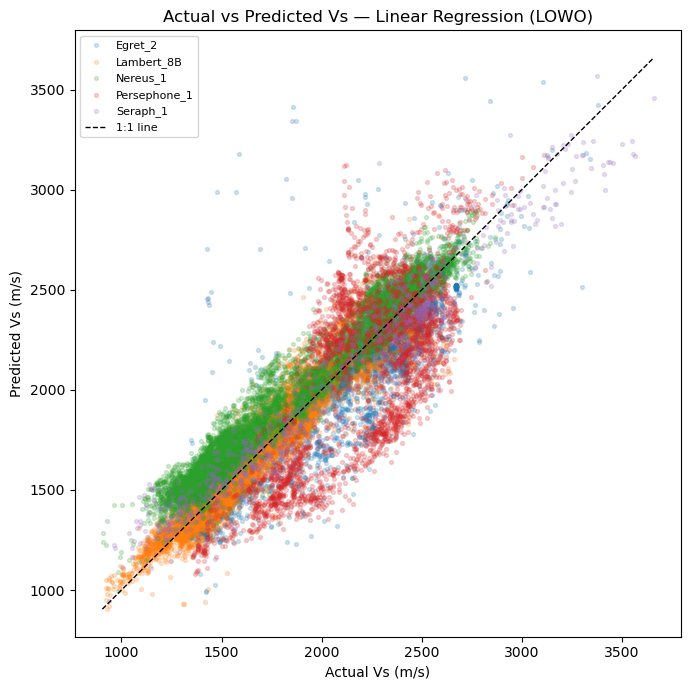

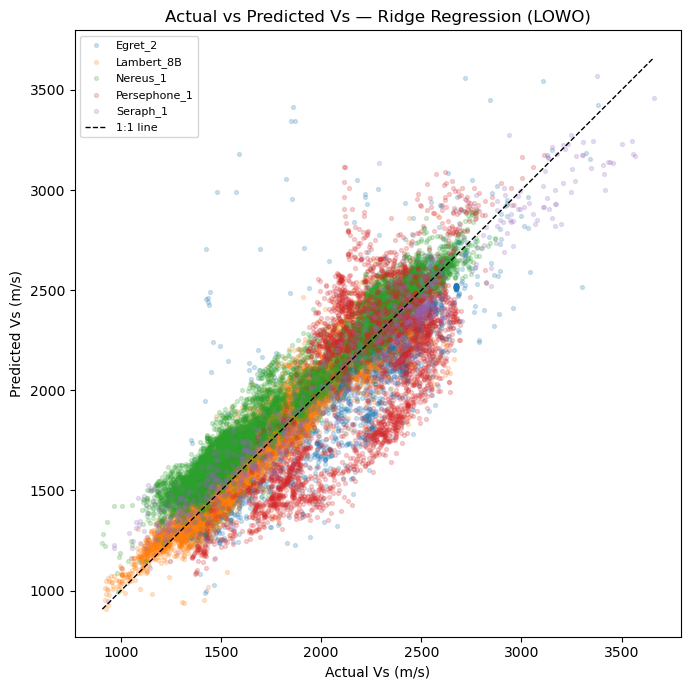

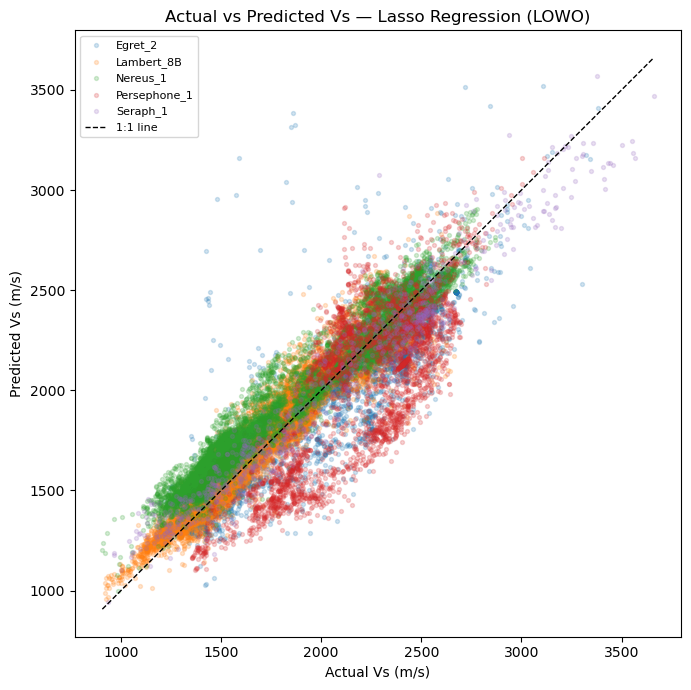

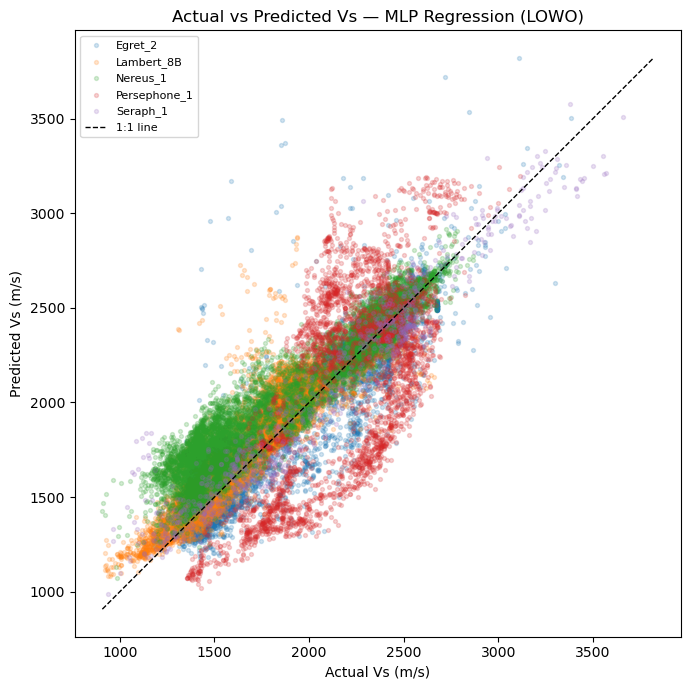

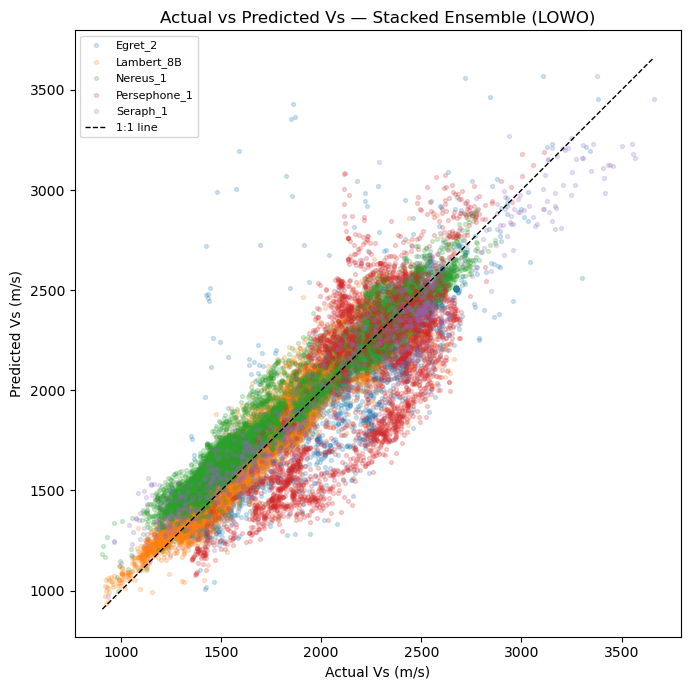

In [11]:
# Lasso alpha selected by LOWO RMSE in notebook 01, Section 8
best_alpha = 7.278953843983153

def fit_predict_linear(train_df, val_df):
    model = LinearRegression()
    model.fit(train_df[features_reg], train_df[target_reg])
    return model.predict(val_df[features_reg])

def fit_predict_ridge(train_df, val_df):
    model = Ridge(alpha=1.0)
    model.fit(train_df[features_reg], train_df[target_reg])
    return model.predict(val_df[features_reg])

def fit_predict_lasso(train_df, val_df):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])
    model = Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)
    model.fit(X_train, train_df[target_reg])
    return model.predict(X_val)

def fit_predict_mlp(train_df, val_df):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])
    model = MLPRegressor(
        hidden_layer_sizes=(32, 16), activation='relu', solver='adam',
        max_iter=2000, early_stopping=True, random_state=42
    )
    model.fit(X_train, train_df[target_reg])
    return model.predict(X_val)

def fit_predict_stack(train_df, val_df):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])
    base_models = [
        ('linear', LinearRegression()),
        ('ridge', Ridge(alpha=1.0)),
        ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
    ]
    model = StackingRegressor(estimators=base_models, final_estimator=Ridge(alpha=1.0), cv=5)
    model.fit(X_train, train_df[target_reg])
    return model.predict(X_val)

model_fitters = {
    'Linear Regression': fit_predict_linear,
    'Ridge Regression': fit_predict_ridge,
    'Lasso Regression': fit_predict_lasso,
    'MLP Regression': fit_predict_mlp,
    'Stacked Ensemble': fit_predict_stack,
}

crossplot_slug = {
    'Linear Regression': 'linear',
    'Ridge Regression': 'ridge',
    'Lasso Regression': 'lasso',
    'MLP Regression': 'mlp',
    'Stacked Ensemble': 'stacked',
}

for model_name, fitter in model_fitters.items():

    actual_all = []
    predicted_all = []
    well_all = []

    for val_well in measured_wells:
        train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
        val_df = data_df[data_df['Well Name'] == val_well]

        pred = fitter(train_df, val_df)

        actual_all.extend(val_df[target_reg].values)
        predicted_all.extend(pred)
        well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

    cross_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Well': well_all})

    fig, ax = plt.subplots(figsize=(7, 7))

    for well_name, group in cross_df.groupby('Well'):
        ax.scatter(group['Actual'], group['Predicted'], s=8, alpha=0.2, label=well_name)

    lims = [cross_df[['Actual', 'Predicted']].min().min(), cross_df[['Actual', 'Predicted']].max().max()]
    ax.plot(lims, lims, 'k--', linewidth=1, label='1:1 line')

    ax.set_xlabel('Actual Vs (m/s)')
    ax.set_ylabel('Predicted Vs (m/s)')
    ax.set_title(f'Actual vs Predicted Vs — {model_name} (LOWO)')
    ax.legend(fontsize=8)
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"actual_vs_predicted_crossplot_{crossplot_slug[model_name]}.png", dpi=300, bbox_inches='tight')
    plt.show()


## 9. Per-well R² / RMSE, split by model

The Section 6 bars show each model's *mean* R²/RMSE across the 5 measured wells — this hides how much that mean varies well-to-well. This grouped bar chart shows the same R²/RMSE, but with one bar per well within each model group, so the well-to-well spread is visible directly (same information as the Section 7 heatmap, as bars instead of a color grid). Styled for use as a figure in the thesis: colorblind-safe categorical palette, a single shared legend outside the plot area, and both a print-resolution PNG and a vector PDF are saved.

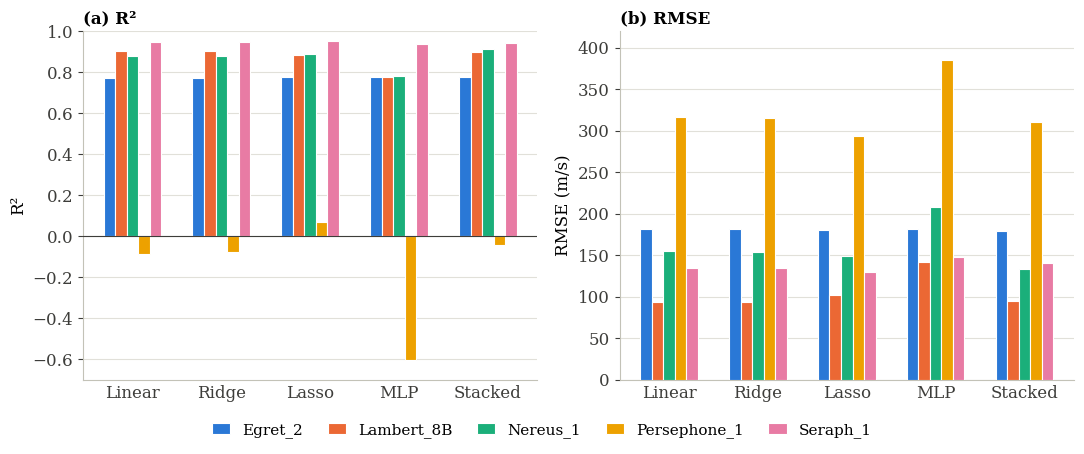

In [19]:
well_order   = [w.replace('_with_formation', '') for w in measured_wells]
model_labels = ['Linear', 'Ridge', 'Lasso', 'MLP', 'Stacked']

# Colourblind-safe colours, one per well (keep the same well colours in every figure)
well_colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

pivot_r2   = results_all.pivot(index='Model', columns='Validation Well', values='R2').reindex(model_order)[well_order]
pivot_rmse = results_all.pivot(index='Model', columns='Validation Well', values='RMSE').reindex(model_order)[well_order]
pivot_r2.to_csv(RESULTS_DIR / 'per_well_r2_by_model.csv')
pivot_rmse.to_csv(RESULTS_DIR / 'per_well_rmse_by_model.csv')

x = np.arange(len(model_order))
n_wells = len(well_order)
bar_width = 0.65 / n_wells

with plt.rc_context({
    'font.family': 'serif', 'font.size': 12,
    'axes.titlesize': 12, 'axes.labelsize': 12,
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'xtick.color': '#3d3d3a', 'ytick.color': '#3d3d3a',
}):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

    for j, well in enumerate(well_order):
        offset = (j - (n_wells - 1) / 2) * bar_width
        axes[0].bar(x + offset, pivot_r2[well], width=bar_width, color=well_colors[j],
                    edgecolor='white', linewidth=0.8, zorder=3, label=well)
        axes[1].bar(x + offset, pivot_rmse[well], width=bar_width, color=well_colors[j],
                    edgecolor='white', linewidth=0.8, zorder=3)

    axes[0].set_title('(a) R²', loc='left', fontweight='bold')
    axes[0].set_ylabel('R²')
    axes[0].set_ylim(-0.7, 1.0)
    axes[0].set_yticks(np.arange(-0.6, 1.01, 0.2))
    axes[0].axhline(0, color='#3d3d3a', linewidth=0.8, zorder=4)   # some R² are negative

    axes[1].set_title('(b) RMSE', loc='left', fontweight='bold')
    axes[1].set_ylabel('RMSE (m/s)')
    axes[1].set_ylim(0, 420)

    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(model_labels)
        ax.tick_params(axis='x', length=0)
        ax.grid(axis='y', color='#e1e0d9', linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # one shared legend under both panels
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=n_wells, frameon=False,
               fontsize=11, handlelength=1.2, columnspacing=1.6, bbox_to_anchor=(0.5, 0))
    plt.tight_layout(rect=(0, 0.07, 1, 1))

    plt.savefig(FIGURES_DIR / "model_comparison_by_well_bar_chart.png", dpi=300, bbox_inches='tight')
    plt.savefig(FIGURES_DIR / "model_comparison_by_well_bar_chart.pdf", bbox_inches='tight')
    plt.show()